1. 임의의 image_id 를 선정하고
2. 해당 image_id 의 gt keypoints를 그리고
3. 특정 epoch별 pred keypoints를 그린다.

그렇게 2개 모델을 비교한다.

In [1]:
import cv2
import numpy as np
from PIL import Image
from IPython.display import display

from contextlib import redirect_stdout

%matplotlib inline
import torch
from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import ToPILImage
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]
kp_labels = ['nose', 'L-ey', 'R-ey', 'L-er', 'R-er',
             'L-sh', 'R-sh', 'L-elb', 'R-elb',
             'L-wr', 'R-wr', 'L-hip', 'R-hip',
             'L-kn', 'R-kn', 'L-ak', 'R-ak']

In [2]:
import random
import orjson

In [3]:
anno_fname = '/home/dev/data/coco//annotations/person_keypoints_val2017.json'
gt = orjson.loads(open(anno_fname).read())
gt.keys()

dict_keys(['info', 'licenses', 'images', 'annotations', 'categories'])

In [4]:
gt['annotations'][0].keys()

dict_keys(['segmentation', 'num_keypoints', 'area', 'iscrowd', 'keypoints', 'image_id', 'bbox', 'category_id', 'id'])

In [5]:
gt_labels_per_image = dict()
for _ann in gt['annotations']:
    image_id = _ann['image_id']
    gt_labels_per_image.setdefault(image_id, [])
    gt_labels_per_image[image_id].append(_ann['keypoints'])

image_pool = list(gt_labels_per_image.keys())
print(f"gt images: {len(image_pool)}")

gt images: 2693


In [52]:
target_epochs = [0, 3, 9, 15, 30, 57]

In [53]:
simdr_preds_per_image_per_epoch = dict()

for ep in target_epochs:
    pred_fname = f"/home/dev/simcc/output/coco/pose_resnet_upfree/res50_upfree_384x288_d256x3_adam_lr1e-3_deconv3_split2_sigma6/results/keypoints_val2017_results_0_ep{ep}.json"
    preds = orjson.loads(open(pred_fname).read())
    _preds_per_image = simdr_preds_per_image_per_epoch.setdefault(ep, {})
    for _pred in preds:
        image_id = _pred['image_id']
        _preds_per_image.setdefault(image_id, [])
        _preds_per_image[image_id].append(_pred['keypoints'])

In [54]:
pose_preds_per_image_per_epoch = dict()

for ep in target_epochs:
    pred_fname = f"/home/dev/pose/results/20250211a/pred_dumps/pred_dump_epoch{ep}"
    preds = orjson.loads(open(pred_fname).read())
    _preds_per_image = pose_preds_per_image_per_epoch.setdefault(ep, {})
    for _pred in preds:
        image_id = _pred['image_id']
        _preds_per_image.setdefault(image_id, [])
        _preds_per_image[image_id].append(_pred['keypoints'])

In [13]:
def get_connected_keypoints(keypoint_idx):
    ret = set()
    for a, b in connectivity:
        if a == keypoint_idx:
            ret.add(b)
        elif b == keypoint_idx:
            ret.add(a)
    return list(ret)

In [14]:
def draw_pred_kp(image_id, epoch):
    preds = preds_per_image_per_epoch[epoch][image_id]
    num_preds = len(preds)
    kps = torch.zeros(num_preds, 17, 2)
    vis = torch.zeros(num_preds, 17)

    for i in range(num_preds):
        _pred = torch.tensor(preds[i]).reshape(17,3)
        kps[i] = _pred[:,0:2]
        vis[i] = _pred[:,2]
    
    fname = str(image_id).zfill(12)
    image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"
    img = read_image(image_path)
    img = draw_keypoints(img, kps, connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=vis)   
    img = to_pil(img)
    plt.imshow(img)
    plt.show()

In [15]:
def draw_pred_kp_with_caption(image_id, epoch, model, draw_sk=True):
    if model == 'simdr':
        preds_per_image_per_epoch = simdr_preds_per_image_per_epoch
    elif model == 'pose':
        preds_per_image_per_epoch = pose_preds_per_image_per_epoch
    else:
        raise Exception(f"Invalid model name: {model}")
    preds = preds_per_image_per_epoch[epoch][image_id]

    fname = str(image_id).zfill(12)
    image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    
    for i, _pred in enumerate(preds):
        # draw keypoints
        pred = np.array(_pred).reshape(17,3)
        for kp_idx, (x, y, vis) in enumerate(pred):
            img = cv2.circle(img, (int(x), int(y)), 3, COLOR_CYAN, 3)
            kp_name = kp_labels[kp_idx]
            img = cv2.putText(img, kp_name, (int(x)+5, int(y)+5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLOR_MAGENTA, 1)
            if draw_sk:
                connected_keypoints = get_connected_keypoints(kp_idx)
                for conn in connected_keypoints:
                    if pred[conn][2] != 0:
                        dst = (int(pred[conn][0]), int(pred[conn][1]))
                        img = cv2.line(img, (int(x), int(y)), dst, COLOR_CYAN, 1)

    plt.imshow(img)
    plt.show()

In [16]:
def compare(gt_img, epoch):
    print(f"Target epoch: {epoch}")
    print("### gt ###")
    plt.imshow(gt_img)
    plt.show()
    print("### pose ###")
    draw_pred_kp_with_caption(image_id=image_id, epoch=epoch, model='pose')
    print("### simdr ###")
    draw_pred_kp_with_caption(image_id=image_id, epoch=epoch, model='simdr')

## 테스트 케이스 모음

### 쉬운 샘플

- 0 epoch 부터 대충 형태 잡히는 케이스
    - 203864
- 130 에서도 안되는 것
    - 128654
 
### SimDR, Pose 성능 차이가 극명하게 보이는 케이스
- 89296

# Test

image id: 269316
num samples: 4


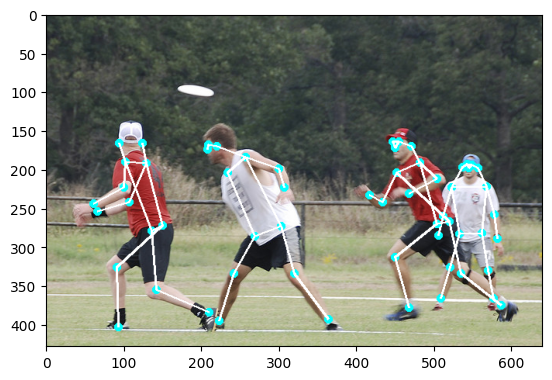

In [126]:
image_id = image_pool[random.randint(0,len(image_pool))]
# image_id = 65736   # tennis (easy)
# image_id = 476119  # skate board (easy)
# image_id = 89296   # baseball (easy)
# image_id = 465180  # elephant - 5 peoples
# image_id = 58350   # 2 peoples
# image_id = 269316  # football - 4 peoples
fname = str(image_id).zfill(12)
image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"

gt_samples = gt_labels_per_image[image_id]
num_samples = len(gt_samples)
kps = torch.zeros(num_samples, 17, 2)
vis = torch.zeros(num_samples, 17)

for i in range(len(gt_samples)):
    _ann = torch.tensor(gt_samples[i]).reshape(17,3)
    kps[i] = _ann[:,0:2]
    vis[i] = _ann[:,2]

print("image id:", image_id)
print("num samples:", num_samples)

img = read_image(image_path)
img = draw_keypoints(img, kps, connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=vis)

gt_img = to_pil(img)
plt.imshow(gt_img)
plt.show()

Target epoch: 0
### gt ###


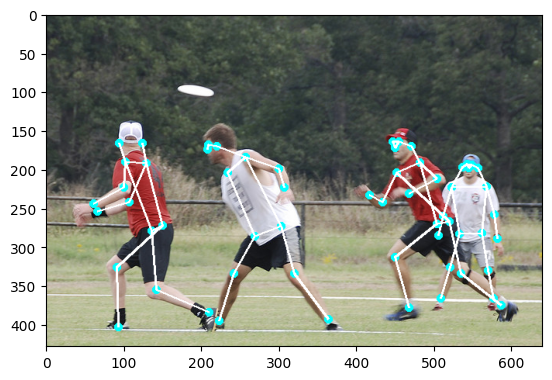

### pose ###


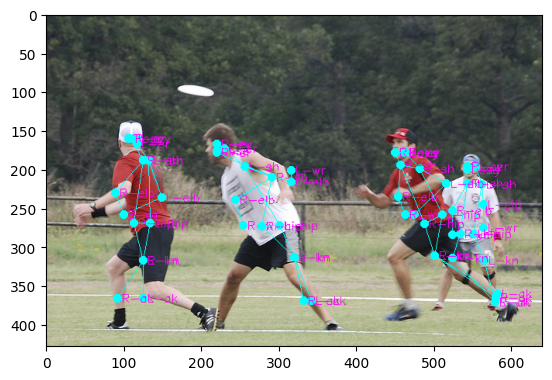

### simdr ###


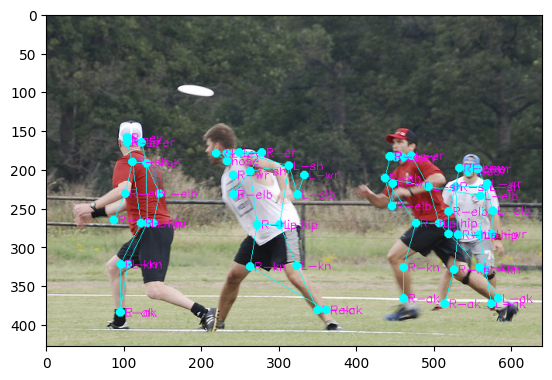

In [127]:
compare(gt_img, epoch=target_epochs[0])

Target epoch: 3
### gt ###


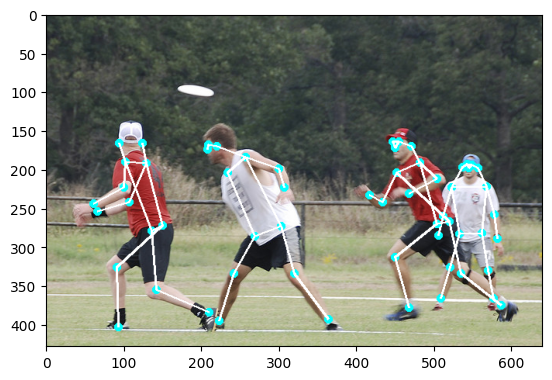

### pose ###


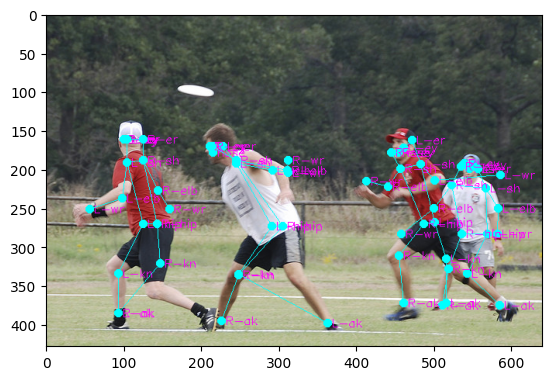

### simdr ###


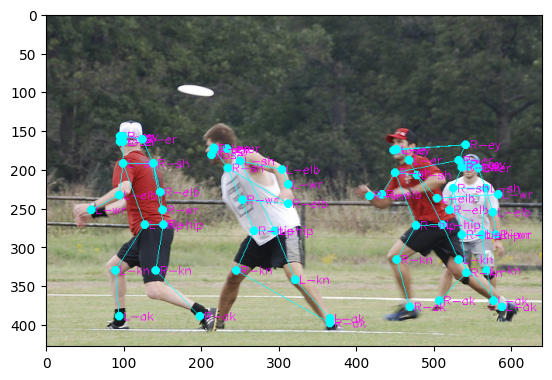

In [128]:
compare(gt_img, epoch=target_epochs[1])

Target epoch: 9
### gt ###


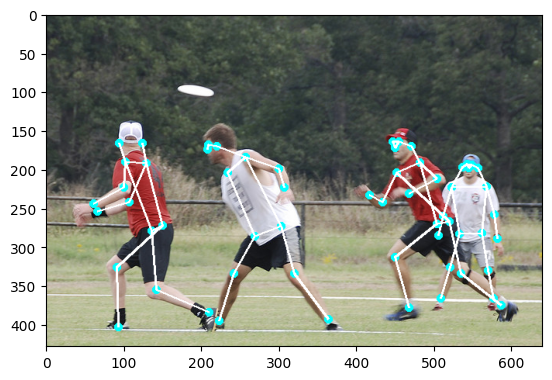

### pose ###


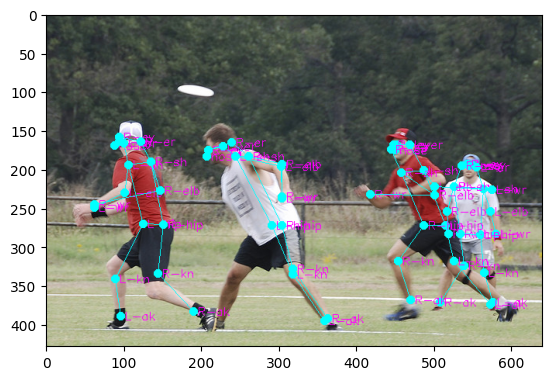

### simdr ###


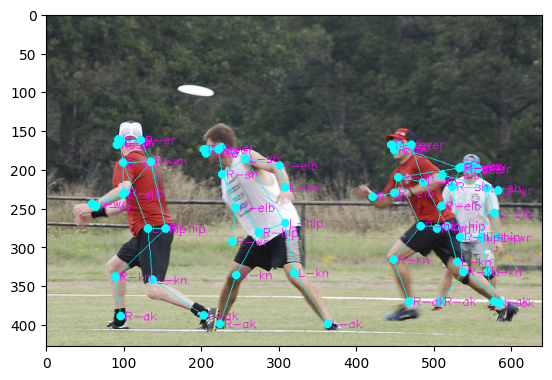

In [129]:
compare(gt_img, epoch=target_epochs[2])

Target epoch: 15
### gt ###


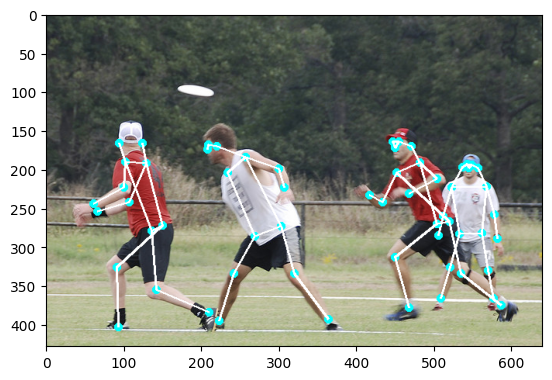

### pose ###


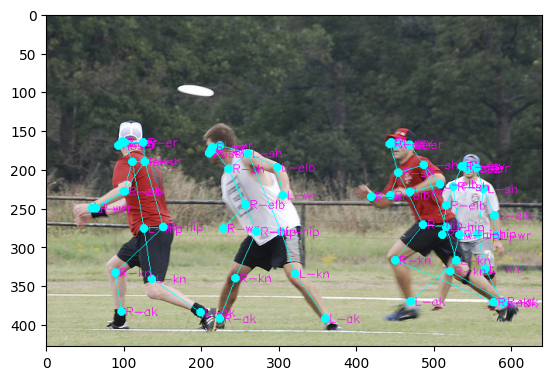

### simdr ###


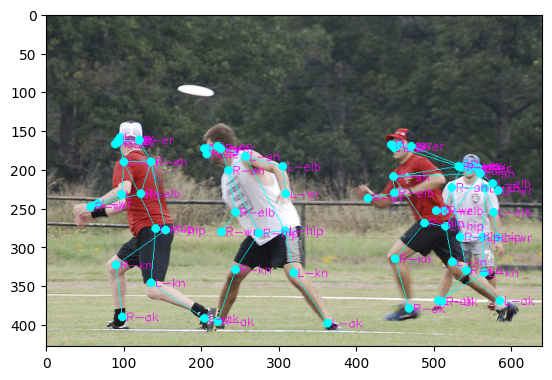

In [130]:
compare(gt_img, epoch=target_epochs[3])

Target epoch: 30
### gt ###


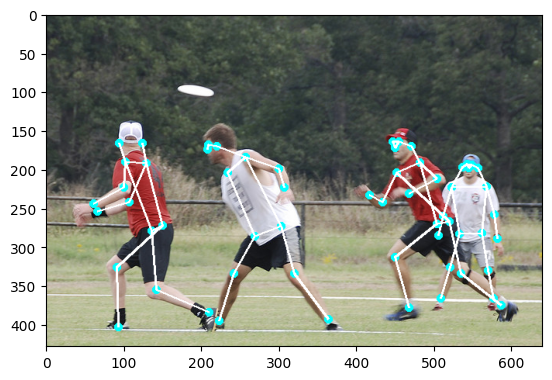

### pose ###


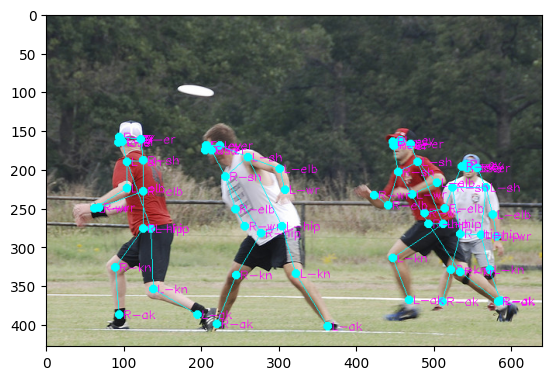

### simdr ###


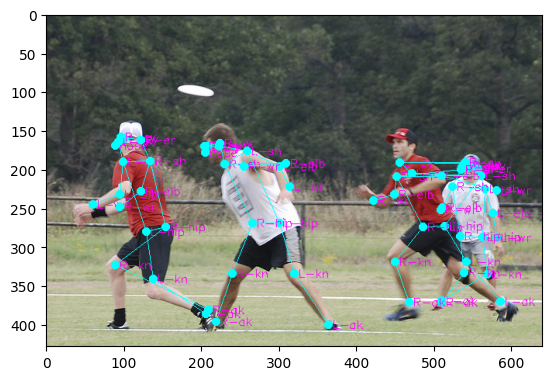

In [131]:
compare(gt_img, epoch=target_epochs[4])

Target epoch: 57
### gt ###


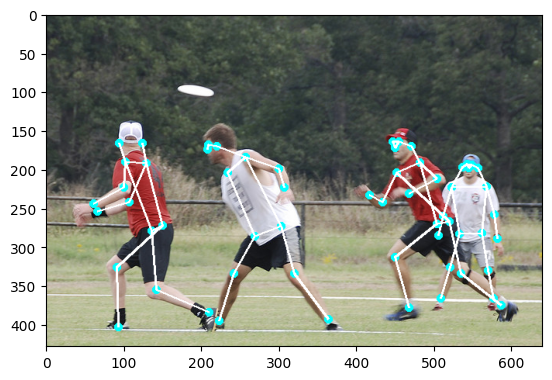

### pose ###


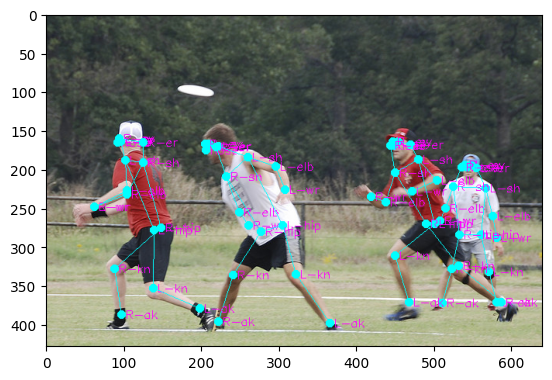

### simdr ###


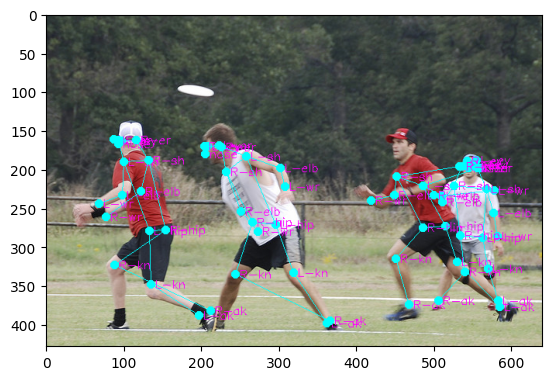

In [132]:
compare(gt_img, epoch=target_epochs[5])